### Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load the data from a CSV file

In [3]:
data = pd.read_csv('Customer_data.csv')
print(data.shape[0])
data.head(5)

25


,CustomerID,Name,Age,Gender,City,Purchase_Amount,Purchase_Date,Product
0,C001,Customer_1,25.0,Female,London,150.75,10/01/2025,Electronics
1,C002,Customer_2,NaN,Male,Lonon,-250.00,NaN,Clothing
2,C003,Customer_3,40.0,NaN,Liverpool,300.00,15/01/2025,Grocery
3,C004,Customer_4,35.0,Female,Birmingham,NaN,01/01/2025,Cosmetics
4,C005,Customer_5,28.0,Male,Manchester,75.00,10/01/2025,Electronics


### Exercise 1

In [ ]:
sum_stats = data.describe() 
sum_stats

np.float64(36.2)

In [7]:
for col in data.columns:
    print(f"Column: {col}")
    print(f"Unique values: {data[col].nunique()}")
    print(f"Missing values: {data[col].isnull().sum()}")
    print("-" * 40)

Column: CustomerID
Unique values: 25
Missing values: 0
----------------------------------------
Column: Name
Unique values: 25
Missing values: 0
----------------------------------------
Column: Age
Unique values: 19
Missing values: 5
----------------------------------------
Column: Gender
Unique values: 2
Missing values: 5
----------------------------------------
Column: City
Unique values: 6
Missing values: 0
----------------------------------------
Column: Purchase_Amount
Unique values: 21
Missing values: 4
----------------------------------------
Column: Purchase_Date
Unique values: 3
Missing values: 5
----------------------------------------
Column: Product
Unique values: 4
Missing values: 0
----------------------------------------


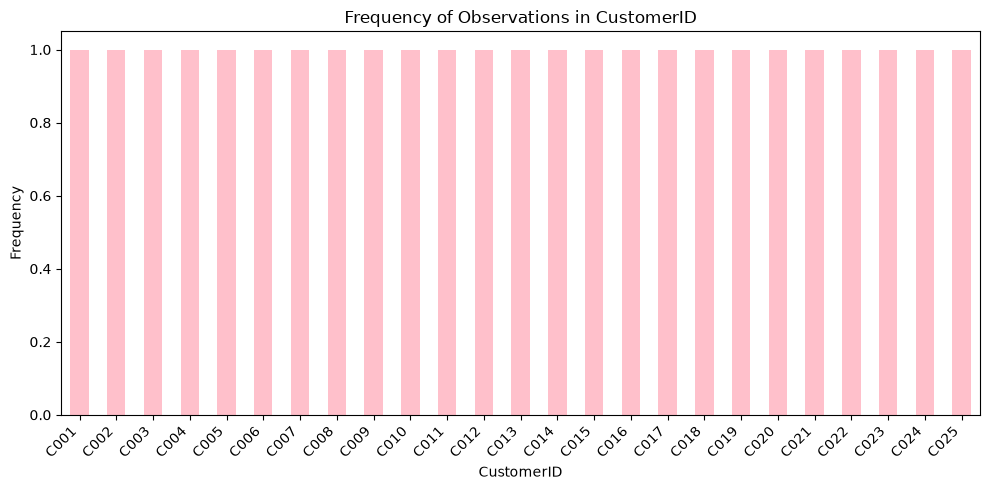

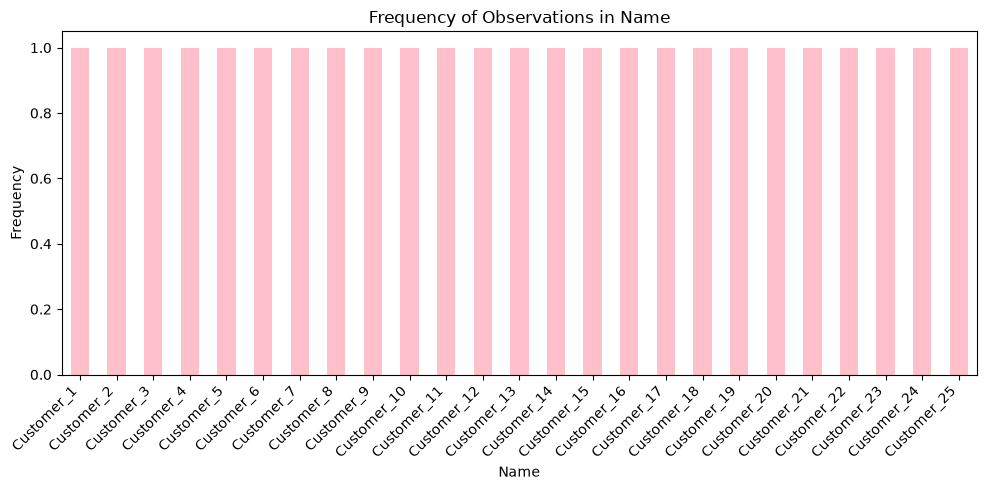

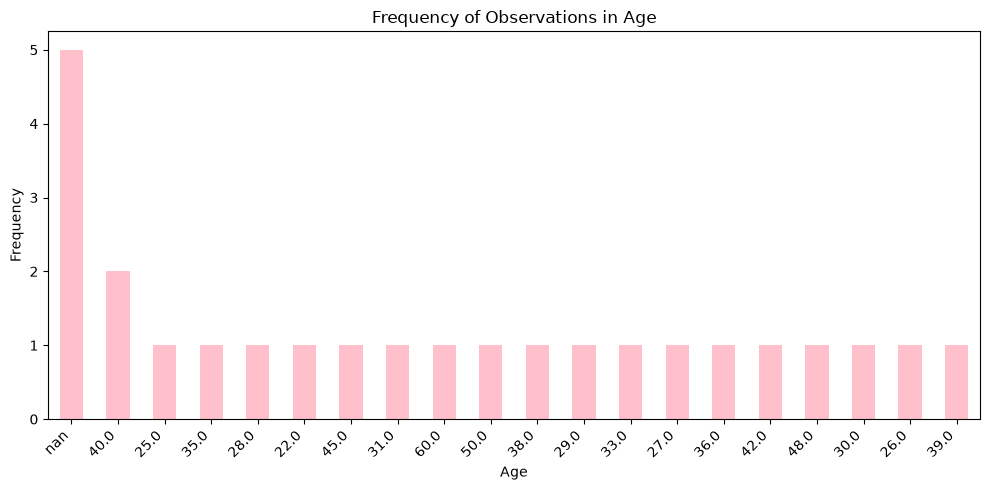

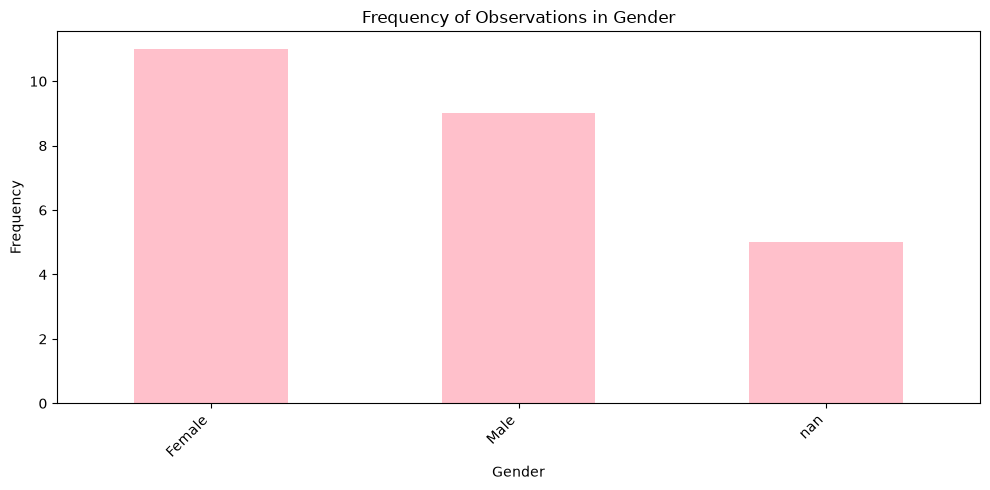

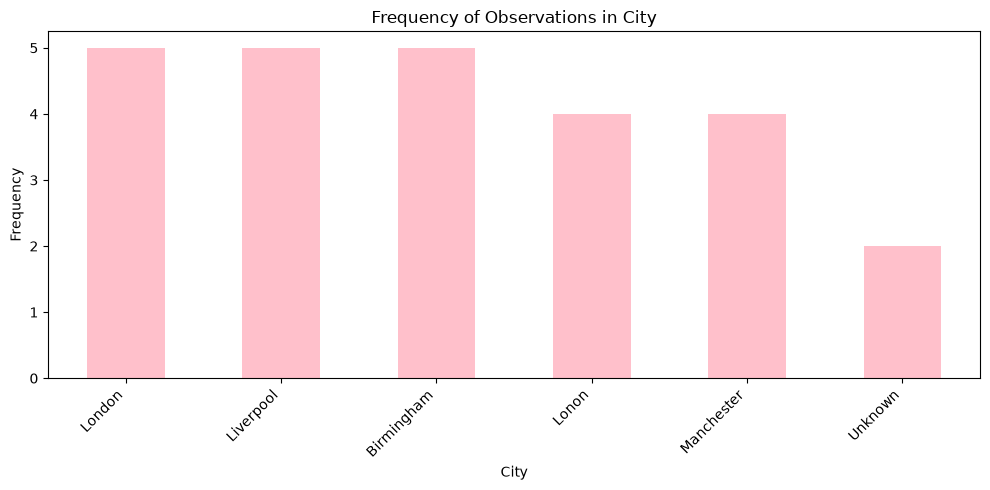

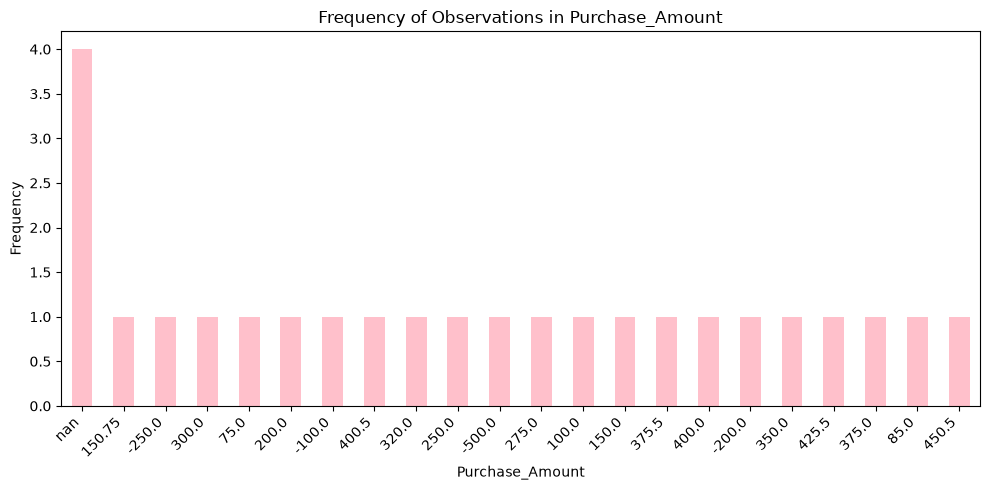

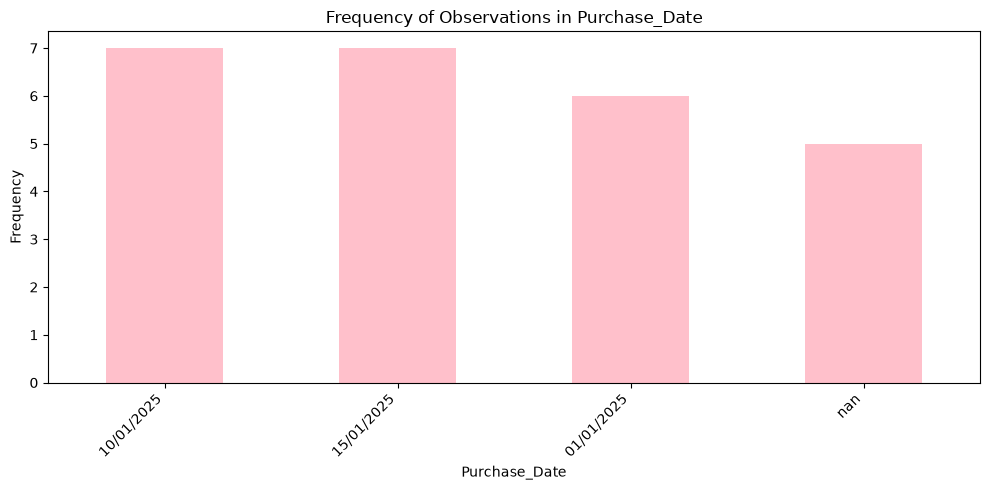

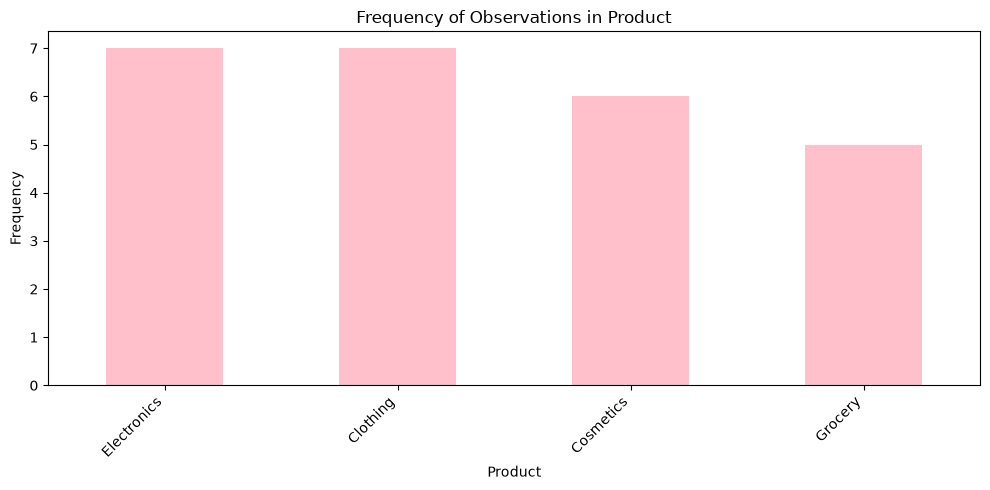

In [13]:
# for col in data.columns:
#     print(f"Column: {col}")
#     print("Volume per observation:")
#     print(data[col].value_counts(dropna=False))
#     print("-" * 40)

for col in data.columns:
    counts = data[col].value_counts(dropna=False)

    plt.figure(figsize=(10, 5))
    counts.plot(kind="bar", color="pink")

    plt.title(f"Frequency of Observations in {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Exercise 2

In [ ]:
# Correct negative purchase amounts
data['Purchase_Amount'] = data['Purchase_Amount'].apply(lambda x: abs(x) if x < 0 else x)
print(data['Purchase_Amount'].min())

# Correct misspellings in the 'City' column + fill missing values with 'London'
data['City'] = data['City'].replace({'Lonon': 'London','Unknown': 'London'})
data['City'] = np.where(data['City']=='Unknown', 'London', data['City'])
print(data['City'].unique())

75.0
<StringArray>
['London', 'Liverpool', 'Birmingham', 'Manchester', 'Unknown']
Length: 5, dtype: str


In [20]:
# Obtain values to be used for replacing missing values
mean_age = sum_stats['Age']['mean']
mean_purchase_amount = data.describe()['Purchase_Amount']['mean']
purchase_date_exp = pd.to_datetime('05/01/2025').date()
mean_gender = data['Gender'].mode()[0]

print(f"Mean Age: {mean_age}")
print(f"Mean Purchase Amount: {mean_purchase_amount}")
print(f"Expected Purchase Date: {purchase_date_exp}")
print(f"Most Common Gender: {mean_gender}")

Mean Age: 36.2
Mean Purchase Amount: 272.98809523809524
Expected Purchase Date: 2025-05-01
Most Common Gender: Female


In [29]:
# Fill in the missing values in the dataset with the calculated values
data['Age'] = data['Age'].fillna(mean_age)
data['Purchase_Amount'] = data['Purchase_Amount'].fillna(mean_purchase_amount)
data['Purchase_Date'] = data['Purchase_Date'].fillna(purchase_date_exp)
data['Purchase_Date'] = data['Purchase_Date'].astype(str)
data['Gender'] = data['Gender'].fillna(mean_gender)

In [30]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Identify categorical and numerical columns
categorical_cols = data.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_cols = data.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numeric_cols)
    ]
)

# Transform the dataset
data_processed = preprocessor.fit_transform(data)

print(data_processed)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 191 stored elements and shape (25, 67)>
  Coords	Values
  (0, 0)	1.0
  (0, 25)	1.0
  (0, 50)	1.0
  (0, 54)	1.0
  (0, 58)	1.0
  (0, 63)	1.0
  (0, 65)	-1.3351511028663468
  (0, 66)	-1.0410818596344606
  (1, 1)	1.0
  (1, 36)	1.0
  (1, 51)	1.0
  (1, 54)	1.0
  (1, 60)	1.0
  (1, 61)	1.0
  (1, 66)	-0.19578584641158395
  (2, 2)	1.0
  (2, 43)	1.0
  (2, 50)	1.0
  (2, 53)	1.0
  (2, 59)	1.0
  (2, 64)	1.0
  (2, 65)	0.45299769561536724
  (2, 66)	0.23005597385183008
  (3, 3)	1.0
  (3, 44)	1.0
  :	:
  (21, 63)	1.0
  (21, 65)	-0.7391015033724422
  (22, 22)	1.0
  (22, 40)	1.0
  (22, 51)	1.0
  (22, 54)	1.0
  (22, 59)	1.0
  (22, 62)	1.0
  (22, 66)	0.8688187042469511
  (23, 23)	1.0
  (23, 41)	1.0
  (23, 50)	1.0
  (23, 53)	1.0
  (23, 57)	1.0
  (23, 64)	1.0
  (23, 65)	-1.215941182967566
  (23, 66)	-1.60106385328085
  (24, 24)	1.0
  (24, 42)	1.0
  (24, 50)	1.0
  (24, 55)	1.0
  (24, 60)	1.0
  (24, 61)	1.0
  (24, 65)	0.3337877757165863
  (24, 66)	1.5

/var/folders/zw/vhv_4k9d6mq1xnd3pyqv3p0w0000gn/T/ipykernel_55120/3596954397.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = data.select_dtypes(


In [ ]:
# Get the new column names after encoding
feature_names = preprocessor.get_feature_names_out()

# Convert the processed data into a DataFrame
data_processed_df = pd.DataFrame(
    data_processed.toarray() if hasattr(data_processed, "toarray")
    else data_processed,
    columns=feature_names,
    index=data.index
)

# Remove the prefixes added by the ColumnTransformer to the column names
data_processed_df.columns = (
    data_processed_df.columns
    .str.replace("cat__", "", regex=False)
    .str.replace("num__", "", regex=False)
)

# Display the first few rows of the processed DataFrame
display(data_processed_df.head())

,cat__CustomerID_C001,cat__CustomerID_C002,cat__CustomerID_C003,cat__CustomerID_C004,cat__CustomerID_C005,cat__CustomerID_C006,cat__CustomerID_C007,cat__CustomerID_C008,cat__CustomerID_C009,cat__CustomerID_C010,...,cat__Purchase_Date_01/01/2025,cat__Purchase_Date_10/01/2025,cat__Purchase_Date_15/01/2025,cat__Purchase_Date_2025-05-01,cat__Product_Clothing,cat__Product_Cosmetics,cat__Product_Electronics,cat__Product_Grocery,num__Age,num__Purchase_Amount
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,-1.335151,-1.041082
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.000000,-0.195786
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.452998,0.230056
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.143052,0.000000
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.977521,-1.686232


### Exercise 3

In [44]:
# Obtain summary statistics of the processed dataset
sum_stats_processed = data.describe()
sum_stats_processed

,Age,Purchase_Amount
count,25.000000,25.000000
mean,36.200000,272.988095
std,8.561542,119.835662
min,22.000000,75.000000
25%,30.000000,200.000000
50%,36.200000,272.988095
75%,40.000000,375.000000
max,60.000000,500.000000


In [ ]:
# Determine the data types and non-null counts of the updated dataset
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       25 non-null     str    
 1   Name             25 non-null     str    
 2   Age              25 non-null     float64
 3   Gender           25 non-null     str    
 4   City             25 non-null     str    
 5   Purchase_Amount  25 non-null     float64
 6   Purchase_Date    25 non-null     str    
 7   Product          25 non-null     str    
dtypes: float64(2), str(6)
memory usage: 1.7 KB


In [35]:
# Average age in each city
data.groupby('City')['Age'].mean()

City
Birmingham    35.800000
Liverpool     35.840000
London        37.488889
Manchester    34.250000
Unknown       36.200000
Name: Age, dtype: float64

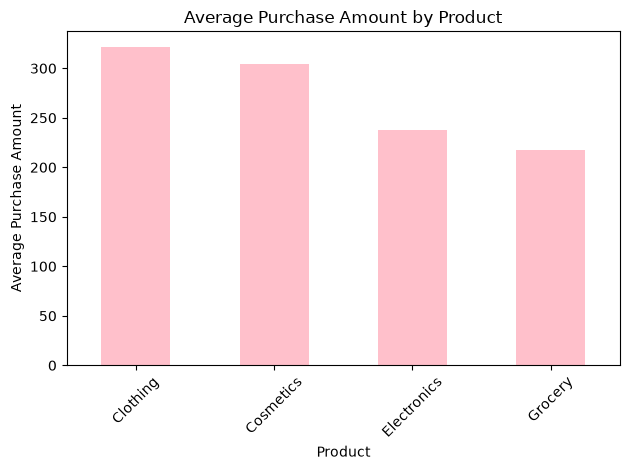

In [ ]:
# Average purchase amount for each product
average_purchase = data.groupby('Product')['Purchase_Amount'].mean()

average_purchase.plot(kind='bar', color='pink')

plt.title('Average Purchase Amount by Product')
plt.xlabel('Product')
plt.ylabel('Average Purchase Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
# Average age and purchase amount for each gender
data.groupby('Gender')[['Age', 'Purchase_Amount']].mean()

,Age,Purchase_Amount
Gender,,
Female,34.262500,289.138393
Male,39.644444,244.276455


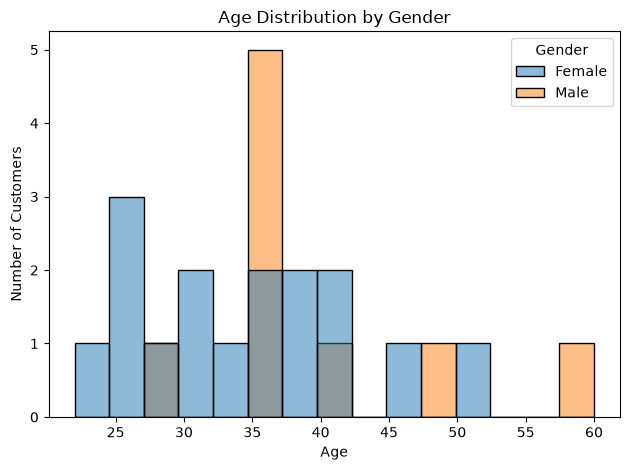

In [43]:
sns.histplot(
    data=data,
    x='Age',
    hue='Gender',
    bins=15,
    multiple='layer',
    alpha=0.5
)

plt.title('Age Distribution by Gender')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()